# Aircraft Engine Predictive Maintenance — Remaining Useful Life (RUL) on NASA C-MAPSS

**Goal:** predict how many flight cycles an engine can still run before failure, using sensor readings, and detect early degradation without labels.

**What this notebook does (every number you quote comes from running it):**

| Part | What | Why it matters |
|---|---|---|
| 1 | Leakage-free pipeline: engine-level train/val split, scaler fit on train only | Results are honest |
| 2 | 3 baselines (mean predictor, Ridge, Random Forest) | Gives a *real* "improvement over baseline" |
| 3 | LSTM and Transformer (with positional encoding), early stopping, **multiple seeds** | Reports mean ± std, not one lucky run |
| 4 | Metrics: RMSE, MAE, R², **NASA PHM08 score**, % late predictions, 95% bootstrap CI | Shows you know why error direction matters |
| 5 | FD001→FD001, FD003→FD003, and **FD001→FD003 (zero-shot)** | Real FD003 number + generalization |
| 6 | Ablations: positional encoding, window size | Evidence for design choices |
| 7 | Error analysis | Shows where the model fails and why |
| 8 | Calibrated autoencoder anomaly detector (AUROC, precision/recall, lead time) | A real detector, not just a plot |

### How to run
1. **Colab:** `Runtime → Change runtime type → T4 GPU` (about 10x faster), then `Runtime → Run all`. When asked, upload the NASA C-MAPSS zip (or any folder containing `train_FD001.txt`, `test_FD001.txt`, `RUL_FD001.txt` and the same three files for `FD003`).
2. **Quick check first:** set `QUICK = True` in the config cell to finish in a few minutes, then set it back to `False` for the final numbers.
3. At the end, the last code cell prints a summary and resume bullets built from **your actual results**.

In [1]:
# ============ 1. Setup & configuration ============
import os, time, math, copy, random, warnings, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, roc_auc_score, precision_recall_fscore_support
warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except Exception:
    display = print

QUICK = False   # True = fast smoke test (few epochs, 1 seed). Use False for final numbers.

CFG = dict(
    WINDOW=30,          # cycles per input window
    RUL_CAP=125,        # piecewise-linear RUL: early life is treated as "healthy = 125"
    EPOCHS=80, PATIENCE=12, BATCH=256, LR=1e-3, WEIGHT_DECAY=1e-4,
    VAL_FRAC=0.2,       # fraction of TRAIN ENGINES held out for validation / early stopping
    SPLIT_SEED=42,
    SEEDS=[0, 1, 2],    # increase to [0,1,2,3,4] for tighter error bars
    ABL_SEEDS=[0, 1],
    AE_EPOCHS=60,
)
if QUICK:
    CFG.update(EPOCHS=8, PATIENCE=3, SEEDS=[0], ABL_SEEDS=[0], AE_EPOCHS=8)

CAP = CFG["RUL_CAP"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "outputs"; os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

print("Device:", DEVICE, "| QUICK =", QUICK)
print({k: v for k, v in CFG.items()})

Device: cuda | QUICK = False
{'WINDOW': 30, 'RUL_CAP': 125, 'EPOCHS': 80, 'PATIENCE': 12, 'BATCH': 256, 'LR': 0.001, 'WEIGHT_DECAY': 0.0001, 'VAL_FRAC': 0.2, 'SPLIT_SEED': 42, 'SEEDS': [0, 1, 2], 'ABL_SEEDS': [0, 1], 'AE_EPOCHS': 60}


In [2]:
# ============ 2. Locate and load the data ============
def find_data_dir():
    for root in [os.getcwd(), "/content", "/kaggle/input"]:
        if os.path.isdir(root):
            for dp, _, fs in os.walk(root):
                if "train_FD001.txt" in fs:
                    return dp
    return None

DATA_DIR = find_data_dir()
if DATA_DIR is None:
    try:   # Colab: ask for the zip
        from google.colab import files
        import zipfile
        print("Upload the C-MAPSS zip file:")
        up = files.upload(); zname = next(iter(up))
        with zipfile.ZipFile(zname) as z: z.extractall("cmapss_data")
        DATA_DIR = find_data_dir()
    except ImportError:
        pass
assert DATA_DIR is not None, "Could not find train_FD001.txt. Put the C-MAPSS .txt files next to this notebook."
print("Data folder:", DATA_DIR)

COLS = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
_RAW = {}
def load_fd(fd):
    """Returns (train_df, test_df, rul_at_end_of_each_test_engine)."""
    if fd not in _RAW:
        rd = lambda n: pd.read_csv(os.path.join(DATA_DIR, f"{n}_{fd}.txt"), sep=r"\s+", header=None).iloc[:, :26]
        tr, te = rd("train"), rd("test")
        tr.columns = COLS; te.columns = COLS
        for d in (tr, te): d["unit"] = d["unit"].astype(int); d["cycle"] = d["cycle"].astype(int)
        rul_end = np.loadtxt(os.path.join(DATA_DIR, f"RUL_{fd}.txt")).astype(np.float32).reshape(-1)
        tr["RUL"] = tr.groupby("unit")["cycle"].transform("max") - tr["cycle"]   # uncapped RUL
        _RAW[fd] = (tr, te, rul_end)
    return _RAW[fd]

Upload the C-MAPSS zip file:


Saving archive (1).zip to archive (1).zip
Data folder: /content/cmapss_data/CMaps


## Data exploration
FD001 and FD003 both have **one operating condition**. FD001 has one fault mode (HPC degradation); FD003 has two (HPC + fan). FD002 and FD004 are the multi-condition sets and are not used here.

FD001: 100 train engines, 100 test engines | train lifetime min/median/max = 128/199/362 | test final-RUL min/median/max = 7/86/145
   constant sensors dropped: ['s1', 's5', 's10', 's16', 's18', 's19']
FD003: 100 train engines, 100 test engines | train lifetime min/median/max = 145/220/525 | test final-RUL min/median/max = 6/77/145
   constant sensors dropped: ['s1', 's5', 's16', 's18', 's19']


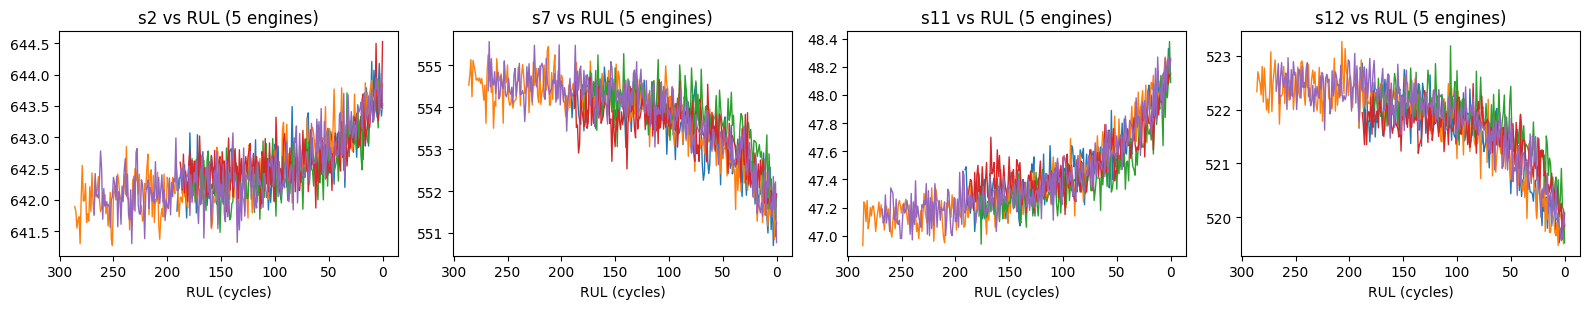

In [3]:
def select_sensors(tr):
    """Keep sensors that actually vary in the training data (drops constants)."""
    return [c for c in COLS[5:] if tr[c].std() > 1e-6]

for fd in ["FD001", "FD003"]:
    tr, te, rul_end = load_fd(fd)
    life = tr.groupby("unit")["cycle"].max()
    print(f"{fd}: {tr.unit.nunique()} train engines, {te.unit.nunique()} test engines | "
          f"train lifetime min/median/max = {life.min()}/{int(life.median())}/{life.max()} | "
          f"test final-RUL min/median/max = {int(rul_end.min())}/{int(np.median(rul_end))}/{int(rul_end.max())}")
    print("   constant sensors dropped:", [c for c in COLS[5:] if c not in select_sensors(tr)])

tr, _, _ = load_fd("FD001")
fig, axs = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, s in zip(axs, ["s2", "s7", "s11", "s12"]):
    for u in [1, 2, 3, 4, 5]:
        g = tr[tr.unit == u]; ax.plot(g["RUL"], g[s], lw=1)
    ax.invert_xaxis(); ax.set_title(f"{s} vs RUL (5 engines)"); ax.set_xlabel("RUL (cycles)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/eda_sensors.png", dpi=130); plt.show()

## Design decisions (be ready to explain these)

* **RUL cap = 125.** Early in life engines show no measurable degradation, so asking the model to tell RUL 300 from RUL 200 is impossible. Capping makes the target learnable. This is standard on C-MAPSS. The same cap is applied to test labels, and this is stated in the results.
* **Split by engine, not by row.** Neighbouring windows of one engine are almost identical; a row-level split would leak. 20% of *training engines* are held out for validation and early stopping.
* **Scaler fit on training engines only.** Test and validation data are only transformed.
* **Test set is touched once**, after all training choices are made. Nothing was tuned on it.
* **Multiple seeds.** Neural nets vary run to run. We report mean ± std over seeds, plus a bootstrap CI over the 100 test engines.
* **NASA score** punishes late predictions (predicting more life than is left) harder than early ones, because a late prediction is the dangerous direction.

In [4]:
# ============ 3. Windowing and preparation ============
def windows(df, sensors, w, pad=False, rul_col="RUL"):
    """Sliding windows per engine. pad=True gives one window for every cycle by repeating the first row."""
    X, yraw, unit, cyc = [], [], [], []
    for u, g in df.groupby("unit", sort=True):
        a = g[sensors].to_numpy(np.float32); r = g[rul_col].to_numpy(np.float32); c = g["cycle"].to_numpy()
        if not pad and len(a) < w:
            continue                                  # engine shorter than one full window (only matters for long windows)
        if pad:
            a = np.vstack([np.repeat(a[:1], w - 1, axis=0), a])
            first = 0
        else:
            first = w - 1
        sw = np.lib.stride_tricks.sliding_window_view(a, w, axis=0)      # (n_windows, f, w)
        sw = np.ascontiguousarray(np.transpose(sw, (0, 2, 1)))          # (n_windows, w, f)
        r, c = r[first:], c[first:]
        k = min(len(sw), len(r))
        X.append(sw[:k]); yraw.append(r[:k]); unit.append(np.full(k, u)); cyc.append(c[:k])
    return dict(X=np.concatenate(X), y_raw=np.concatenate(yraw), unit=np.concatenate(unit), cycle=np.concatenate(cyc))

def prepare(train_fd, window=None):
    """Engine-level split, scaler fit on train engines only, training/validation windows."""
    w = window or CFG["WINDOW"]
    tr, _, _ = load_fd(train_fd)
    sensors = select_sensors(tr)
    units = np.sort(tr["unit"].unique())
    perm = np.random.RandomState(CFG["SPLIT_SEED"]).permutation(units)
    n_val = int(round(len(units) * CFG["VAL_FRAC"]))
    val_units = set(perm[:n_val].tolist())
    tr_df = tr[~tr["unit"].isin(val_units)].copy()
    va_df = tr[tr["unit"].isin(val_units)].copy()
    scaler = MinMaxScaler().fit(tr_df[sensors])
    tr_df[sensors] = scaler.transform(tr_df[sensors]); va_df[sensors] = scaler.transform(va_df[sensors])
    Wt, Wv = windows(tr_df, sensors, w), windows(va_df, sensors, w)
    return dict(train_fd=train_fd, window=w, cap=CAP, sensors=sensors, scaler=scaler,
                n_train_engines=len(units) - n_val, n_val_engines=n_val,
                Xtr=Wt["X"], ytr=np.minimum(Wt["y_raw"], CAP).astype(np.float32), ytr_raw=Wt["y_raw"],
                Xva=Wv["X"], yva=np.minimum(Wv["y_raw"], CAP).astype(np.float32))

def build_test(prep, test_fd):
    """Test inputs using the *training* sensors and scaler (so a different test_fd = zero-shot transfer)."""
    _, te, rul_end = load_fd(test_fd)
    te = te.copy(); w = prep["window"]; sensors = prep["sensors"]
    last_cycle = te.groupby("unit")["cycle"].transform("max")
    te["RUL"] = rul_end[te["unit"].to_numpy() - 1] + (last_cycle - te["cycle"])   # true RUL at every observed cycle
    te[sensors] = prep["scaler"].transform(te[sensors])
    A = windows(te, sensors, w, pad=False)     # every full window (used by the anomaly detector)
    P = windows(te, sensors, w, pad=True)      # one per cycle; we take the last per engine (handles short engines)
    last_idx = pd.Series(np.arange(len(P["unit"]))).groupby(P["unit"]).max().to_numpy()
    return dict(fd=test_fd, X_last=P["X"][last_idx], y_last_raw=rul_end, y_last=np.minimum(rul_end, CAP).astype(np.float32),
                X_all=A["X"], y_all_raw=A["y_raw"], unit_all=A["unit"], cycle_all=A["cycle"], n_engines=len(rul_end))

_p = prepare("FD001")
print(f"FD001 -> train windows {_p['Xtr'].shape}, val windows {_p['Xva'].shape}, sensors kept: {len(_p['sensors'])}")
print(f"   train engines: {_p['n_train_engines']}, validation engines: {_p['n_val_engines']}")
_t = build_test(_p, "FD001"); print(f"   test engines: {_t['n_engines']}, last-window input {_t['X_last'].shape}")
del _p, _t

FD001 -> train windows (14241, 30, 15), val windows (3490, 30, 15), sensors kept: 15
   train engines: 80, validation engines: 20
   test engines: 100, last-window input (100, 30, 15)


In [5]:
# ============ 4. Metrics and classical baselines ============
def evaluate(y_true, y_pred):
    d = y_pred - y_true                                   # > 0 means predicted MORE life than remains (late)
    return dict(RMSE=float(np.sqrt(np.mean(d ** 2))), MAE=float(np.mean(np.abs(d))),
                R2=float(r2_score(y_true, y_pred)),
                NASA=float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1))),   # PHM08 score, lower is better
                Late_pct=float(np.mean(d > 0) * 100))

def bootstrap_rmse_ci(y, p, n=2000, seed=0):
    rng = np.random.RandomState(seed); e2 = (p - y) ** 2; m = len(y)
    stats = [np.sqrt(e2[rng.randint(0, m, m)].mean()) for _ in range(n)]
    return np.percentile(stats, [2.5, 97.5])

def handcrafted(X):
    """Window -> last values, mean, std, slope per sensor (features for the Random Forest)."""
    t = np.arange(X.shape[1]) - (X.shape[1] - 1) / 2
    slope = (X * t[None, :, None]).sum(1) / (t ** 2).sum()
    return np.hstack([X[:, -1], X.mean(1), X.std(1), slope])

def run_baselines(prep, tests, train_fd):
    cap = prep["cap"]; rows, preds = [], {}
    n = len(prep["Xtr"])
    ridge = Ridge(alpha=1.0).fit(prep["Xtr"].reshape(n, -1), prep["ytr"])
    rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=0).fit(handcrafted(prep["Xtr"]), prep["ytr"])
    for te_fd, ts in tests.items():
        cand = {
            "Mean predictor": np.full(len(ts["y_last"]), prep["ytr"].mean(), dtype=np.float32),
            "Ridge (flattened window)": ridge.predict(ts["X_last"].reshape(len(ts["X_last"]), -1)),
            "Random forest (engineered feats)": rf.predict(handcrafted(ts["X_last"])),
        }
        for name, p in cand.items():
            p = np.clip(p, 0, cap); preds[(te_fd, name)] = p
            rows.append(dict(Train=train_fd, Test=te_fd, Model=name, Seed=0, Params=np.nan, Train_s=np.nan, **evaluate(ts["y_last"], p)))
    return rows, preds

def first_alarm(e, thr, k=3):
    """Index of the first window where the error stays above thr for k consecutive windows (else None)."""
    run = np.convolve((e > thr).astype(int), np.ones(k, dtype=int), "valid")
    idx = np.where(run == k)[0]
    return int(idx[0] + k - 1) if len(idx) else None

def evaluate_detector(err, y_raw, unit, thr, cap=None):
    """Window-level AUROC/precision/recall/F1 (near-failure vs healthy) and engine-level alarm behaviour."""
    cap = cap or CAP
    healthy, near = y_raw >= cap, y_raw <= 30
    m = healthy | near
    lab = near[m].astype(int)
    auroc = roc_auc_score(lab, err[m])
    pr, rc, f1, _ = precision_recall_fscore_support(lab, (err[m] > thr).astype(int), average="binary", zero_division=0)
    false_alarm, warned, silent, lead = 0, 0, 0, []
    for u in np.unique(unit):
        mm = unit == u
        a = first_alarm(err[mm], thr)
        if a is None: silent += 1
        elif float(y_raw[mm][a]) >= cap: false_alarm += 1
        else: warned += 1; lead.append(float(y_raw[mm][a]))
    return dict(auroc=float(auroc), precision=float(pr), recall=float(rc), f1=float(f1), n_healthy=int(healthy.sum()),
                n_near=int(near.sum()), warned=warned, false_alarm=false_alarm, silent=silent,
                median_lead=float(np.median(lead)) if lead else float("nan"),
                mean_lead=float(np.mean(lead)) if lead else float("nan"))

## Models
Two sequence models, same training recipe, so the comparison is fair.

* **LSTM:** 2 layers, hidden size 64, dropout 0.2.
* **Transformer encoder:** sinusoidal **positional encoding**, 2 layers, 4 heads, dropout 0.1, pre-norm. Without positional encoding the attention layers do not know the order of the 30 cycles, which is why the first version of this project overfit and underperformed.

Both are trained with AdamW, gradient clipping, a learning-rate scheduler, and **early stopping on the validation engines**. The best validation checkpoint is the one that gets tested.

In [6]:
# ============ 5. Models ============
class LSTMReg(nn.Module):
    def __init__(self, n_feat, hidden=64, layers=2, drop=0.2):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, layers, batch_first=True, dropout=drop)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Dropout(drop), nn.Linear(32, 1))
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)

class PosEnc(nn.Module):
    def __init__(self, d, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d, 2).float() * (-math.log(10000.0) / d))
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x):
        return x + self.pe[:, : x.size(1)]

class TransformerReg(nn.Module):
    def __init__(self, n_feat, d_model=64, nhead=4, layers=2, ff=128, drop=0.1, use_pos=True):
        super().__init__()
        self.inp = nn.Linear(n_feat, d_model)
        self.pos = PosEnc(d_model) if use_pos else nn.Identity()
        layer = nn.TransformerEncoderLayer(d_model, nhead, ff, drop, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.Linear(2 * d_model, 32), nn.ReLU(), nn.Dropout(drop), nn.Linear(32, 1))
    def forward(self, x):
        h = self.enc(self.pos(self.inp(x)))
        return self.head(torch.cat([h[:, -1], h.mean(1)], dim=-1)).squeeze(-1)

MODEL_BUILDERS = {
    "LSTM": lambda nf: LSTMReg(nf),
    "Transformer": lambda nf: TransformerReg(nf, use_pos=True),
}
count_params = lambda m: int(sum(p.numel() for p in m.parameters() if p.requires_grad))
print({k: count_params(v(15)) for k, v in MODEL_BUILDERS.items()}, "trainable parameters (15 sensors)")

{'LSTM': 56129, 'Transformer': 72129} trainable parameters (15 sensors)


In [7]:
# ============ 6. Training with validation and early stopping ============
@torch.no_grad()
def predict_np(model, X, cap, bs=2048):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(model(torch.from_numpy(X[i:i + bs]).to(DEVICE)).cpu().numpy())
    return np.clip(np.concatenate(out), 0, 1) * cap          # model predicts RUL / cap

def train_model(build_fn, prep, seed):
    set_seed(seed)
    cap, B = prep["cap"], CFG["BATCH"]
    model = build_fn(prep["Xtr"].shape[2]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=5)
    Xt = torch.from_numpy(prep["Xtr"]).to(DEVICE); yt = torch.from_numpy(prep["ytr"] / cap).to(DEVICE)
    g = torch.Generator(); g.manual_seed(seed)
    n = len(Xt); loss_fn = nn.MSELoss()
    hist = dict(train_rmse=[], val_rmse=[], lr=[])
    best_val, best_state, best_ep, wait = float("inf"), None, 0, 0
    t0 = time.time()
    for ep in range(CFG["EPOCHS"]):
        model.train(); perm = torch.randperm(n, generator=g).to(DEVICE); tot = 0.0
        for i in range(0, n, B):
            idx = perm[i:i + B]
            opt.zero_grad()
            loss = loss_fn(model(Xt[idx]), yt[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tot += loss.item() * len(idx)
        val_rmse = float(np.sqrt(np.mean((predict_np(model, prep["Xva"], cap) - prep["yva"]) ** 2)))
        sched.step(val_rmse)
        hist["train_rmse"].append(math.sqrt(tot / n) * cap); hist["val_rmse"].append(val_rmse); hist["lr"].append(opt.param_groups[0]["lr"])
        if val_rmse < best_val - 1e-4:
            best_val, best_ep, wait = val_rmse, ep + 1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= CFG["PATIENCE"]: break
    model.load_state_dict(best_state)
    return model, hist, dict(val_rmse=best_val, best_epoch=best_ep, time=time.time() - t0)

def run_experiment(train_fd, test_fds, model_names=("LSTM", "Transformer"), seeds=None, builders=None, window=None, verbose=True):
    seeds = seeds or CFG["SEEDS"]; builders = builders or MODEL_BUILDERS
    prep = prepare(train_fd, window)
    tests = {t: build_test(prep, t) for t in test_fds}
    rows, preds, hists = [], {}, {}
    for name in model_names:
        for seed in seeds:
            model, hist, info = train_model(builders[name], prep, seed)
            npar = count_params(model)
            msg = []
            for t, ts in tests.items():
                p = predict_np(model, ts["X_last"], prep["cap"])
                m = evaluate(ts["y_last"], p)
                rows.append(dict(Train=train_fd, Test=t, Model=name, Seed=seed, Val_RMSE=info["val_rmse"], Params=npar,
                                 Train_s=info["time"], Best_epoch=info["best_epoch"], **m))
                preds.setdefault((t, name), []).append(p); msg.append(f"test {t} RMSE {m['RMSE']:.2f}")
            hists[(name, seed)] = hist
            if verbose:
                print(f"  [{train_fd}] {name:<12} seed {seed}: best epoch {info['best_epoch']:>3}, val RMSE {info['val_rmse']:.2f}, "
                      + ", ".join(msg) + f"  ({info['time']:.0f}s)")
    return dict(prep=prep, tests=tests, rows=rows, preds=preds, hists=hists)

## Main experiments
Three settings, all evaluated on the official test engines:

* **FD001 → FD001** (main result)
* **FD003 → FD003** (in-domain on the harder dataset; this is the standard way to report an "FD003 RMSE")
* **FD001 → FD003** (zero-shot: the model never saw FD003, and uses FD001's scaler and sensors)

Expect this cell to take a few minutes on a GPU, longer on CPU.

In [8]:
# ============ 7. Run everything ============
RUNS, BASE_ROWS, PRED, YTRUE = {}, [], {}, {}
plan = {"FD001": ["FD001", "FD003"], "FD003": ["FD003"]}
t_start = time.time()
for tr_fd, te_list in plan.items():
    print(f"\n=== Train on {tr_fd}, test on {te_list} ===")
    res = run_experiment(tr_fd, te_list)
    RUNS[tr_fd] = res
    brows, bpreds = run_baselines(res["prep"], res["tests"], tr_fd)
    BASE_ROWS += brows
    for (te_fd, name), plist in res["preds"].items(): PRED[(tr_fd, te_fd, name)] = np.mean(plist, axis=0)   # seed-ensemble
    for (te_fd, name), p in bpreds.items(): PRED[(tr_fd, te_fd, name)] = p
    for te_fd, ts in res["tests"].items(): YTRUE[(tr_fd, te_fd)] = ts["y_last"]
print(f"\nDone in {(time.time() - t_start) / 60:.1f} min")
ALL = pd.concat([pd.DataFrame(BASE_ROWS)] + [pd.DataFrame(r["rows"]) for r in RUNS.values()], ignore_index=True)
ALL.to_csv(f"{OUT_DIR}/per_seed_results.csv", index=False)


=== Train on FD001, test on ['FD001', 'FD003'] ===
  [FD001] LSTM         seed 0: best epoch  28, val RMSE 11.80, test FD001 RMSE 13.56, test FD003 RMSE 49.10  (10s)
  [FD001] LSTM         seed 1: best epoch  35, val RMSE 11.97, test FD001 RMSE 13.35, test FD003 RMSE 49.14  (10s)
  [FD001] LSTM         seed 2: best epoch  23, val RMSE 11.92, test FD001 RMSE 13.23, test FD003 RMSE 49.08  (8s)
  [FD001] Transformer  seed 0: best epoch  18, val RMSE 11.97, test FD001 RMSE 13.24, test FD003 RMSE 42.21  (14s)
  [FD001] Transformer  seed 1: best epoch  73, val RMSE 11.54, test FD001 RMSE 12.55, test FD003 RMSE 35.15  (37s)
  [FD001] Transformer  seed 2: best epoch  25, val RMSE 11.60, test FD001 RMSE 13.63, test FD003 RMSE 38.79  (17s)

=== Train on FD003, test on ['FD003'] ===
  [FD003] LSTM         seed 0: best epoch  44, val RMSE 12.55, test FD003 RMSE 13.35  (15s)
  [FD003] LSTM         seed 1: best epoch  61, val RMSE 11.53, test FD003 RMSE 12.32  (20s)
  [FD003] LSTM         seed 2: b

In [9]:
# ============ 8. Results table ============
def pm(vals, nd=2):
    vals = np.asarray(vals, dtype=float)
    if len(vals) > 1: return f"{vals.mean():.{nd}f} ± {vals.std(ddof=1):.{nd}f}"
    return f"{vals.mean():.{nd}f}"

BASELINE_NAMES = ["Mean predictor", "Ridge (flattened window)", "Random forest (engineered feats)"]
table = []
for (tr_fd, te_fd), sub in ALL.groupby(["Train", "Test"], sort=False):
    base_rmse = sub[sub.Model == "Mean predictor"].RMSE.mean()
    classical = min(sub[sub.Model == m].RMSE.mean() for m in BASELINE_NAMES[1:])
    for model, g in sub.groupby("Model", sort=False):
        r = g.RMSE.mean()
        y, p = YTRUE[(tr_fd, te_fd)], PRED[(tr_fd, te_fd, model)]
        lo, hi = bootstrap_rmse_ci(y, p)
        is_base = model in BASELINE_NAMES
        table.append({
            "Setting": f"{tr_fd} → {te_fd}", "Model": model,
            "RMSE": pm(g.RMSE), "MAE": pm(g.MAE), "R²": pm(g.R2, 3), "NASA score": pm(g.NASA, 0), "Late %": pm(g.Late_pct, 0),
            "Params": "-" if is_base else f"{int(g.Params.iloc[0]):,}", "Train time (s)": "-" if is_base else f"{g.Train_s.mean():.0f}",
            "ΔRMSE vs mean-predictor": "-" if model == "Mean predictor" else f"{(base_rmse - r) / base_rmse * 100:.1f}%",
            "ΔRMSE vs best classical": "-" if is_base else f"{(classical - r) / classical * 100:+.1f}%",
            "Seed-ensemble RMSE [95% CI]": f"{np.sqrt(np.mean((p - y) ** 2)):.2f} [{lo:.2f}, {hi:.2f}]",
        })
RESULTS = pd.DataFrame(table)
RESULTS.to_csv(f"{OUT_DIR}/results_table.csv", index=False)
display(RESULTS)
print("\nRMSE/MAE/R²/NASA score are mean ± std over seeds on the official test engines (RUL capped at", CAP, "for both train and test).")
print("'Late %' = share of engines where the model predicted MORE remaining life than the truth (the risky direction).")
print("'ΔRMSE vs best classical' compares each deep model to the better of Ridge / Random forest in the same setting; negative means WORSE.")

,Setting,Model,RMSE,MAE,R²,NASA score,Late %,Params,Train time (s),ΔRMSE vs mean-predictor,ΔRMSE vs best classical,Seed-ensemble RMSE [95% CI]
0,FD001 → FD001,Mean predictor,40.58,35.07,-0.025,18669,45,-,-,-,-,"40.58 [36.73, 44.43]"
1,FD001 → FD001,Ridge (flattened window),14.72,11.91,0.865,363,54,-,-,63.7%,-,"14.72 [12.66, 16.84]"
2,FD001 → FD001,Random forest (engineered feats),12.81,9.30,0.898,259,60,-,-,68.4%,-,"12.81 [10.26, 15.18]"
3,FD001 → FD001,LSTM,13.38 ± 0.17,9.96 ± 0.18,0.889 ± 0.003,310 ± 16,58 ± 4,"56,129",9,67.0%,-4.4%,"13.27 [11.08, 15.42]"
4,FD001 → FD001,Transformer,13.14 ± 0.55,9.77 ± 0.48,0.892 ± 0.009,308 ± 50,61 ± 4,"72,129",23,67.6%,-2.5%,"12.74 [10.57, 14.94]"
5,FD001 → FD003,Mean predictor,39.80,34.35,-0.032,17382,53,-,-,-,-,"39.80 [35.97, 43.65]"
6,FD001 → FD003,Ridge (flattened window),53.62,37.83,-0.874,1029729,69,-,-,-34.7%,-,"53.62 [45.56, 60.96]"
7,FD001 → FD003,Random forest (engineered feats),19.39,14.27,0.755,2266,67,-,-,51.3%,-,"19.39 [16.01, 22.96]"
8,FD001 → FD003,LSTM,49.11 ± 0.03,31.09 ± 0.17,-0.572 ± 0.002,1017761 ± 36,70 ± 1,"56,129",9,-23.4%,-153.2%,"49.09 [40.71, 57.07]"
9,FD001 → FD003,Transformer,38.72 ± 3.54,25.90 ± 1.99,0.017 ± 0.178,82142 ± 43500,64 ± 3,"72,129",23,2.7%,-99.7%,"35.16 [29.43, 40.42]"



RMSE/MAE/R²/NASA score are mean ± std over seeds on the official test engines (RUL capped at 125 for both train and test).
'Late %' = share of engines where the model predicted MORE remaining life than the truth (the risky direction).
'ΔRMSE vs best classical' compares each deep model to the better of Ridge / Random forest in the same setting; negative means WORSE.


## Learning curves and error analysis
If validation error tracks training error, the model is not overfitting. The error-by-RUL table shows *where* the model is weak, which is the question an interviewer will ask next.

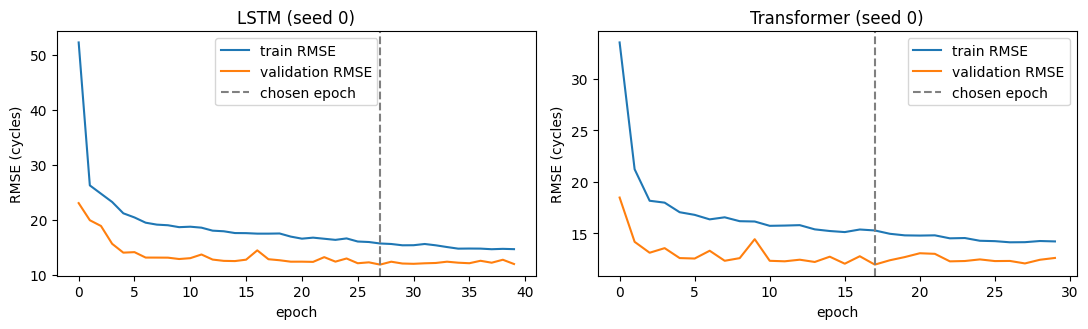

Best deep model on FD001 (seed-ensemble): Transformer


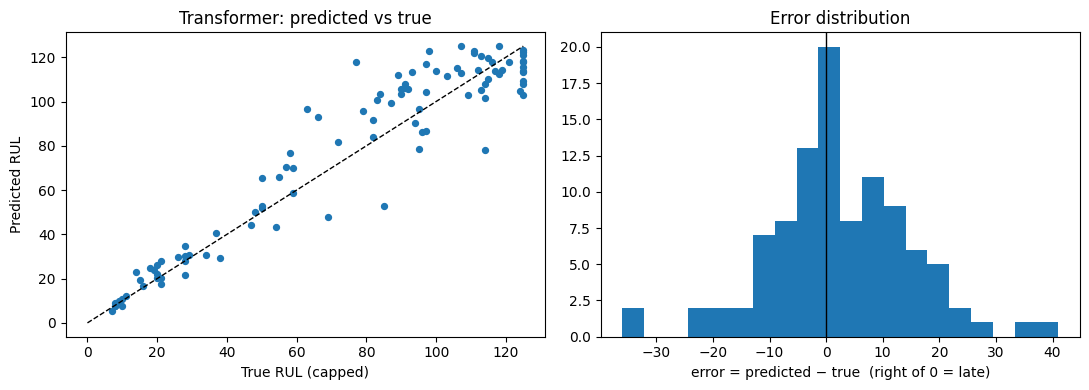


Error by true-RUL range (a positive mean error means the model is late / over-optimistic):


,Engines,RMSE,Mean_error
bin,,,
0-25,19,3.850000,1.92
25-50,14,5.850000,1.42
50-75,10,18.080000,9.20
75-100,24,17.940001,9.61
100-125,33,11.650000,-4.01



Five worst engines:


,engine,true,pred,error
66,67,77.0,118.000000,41.000000
44,45,114.0,78.000000,-36.000000
78,79,63.0,96.400002,33.400002
92,93,85.0,52.799999,-32.200001
26,27,66.0,93.099998,27.100000


In [10]:
# ============ 9. Learning curves + error analysis (FD001) ============
res1 = RUNS["FD001"]; seed0 = CFG["SEEDS"][0]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, name in zip(axs, ["LSTM", "Transformer"]):
    h = res1["hists"][(name, seed0)]
    ax.plot(h["train_rmse"], label="train RMSE"); ax.plot(h["val_rmse"], label="validation RMSE")
    ax.axvline(int(ALL[(ALL.Train == "FD001") & (ALL.Model == name) & (ALL.Seed == seed0)].Best_epoch.iloc[0]) - 1, ls="--", c="gray", label="chosen epoch")
    ax.set_title(f"{name} (seed {seed0})"); ax.set_xlabel("epoch"); ax.set_ylabel("RMSE (cycles)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/learning_curves.png", dpi=130); plt.show()

y = YTRUE[("FD001", "FD001")]
deep = ["LSTM", "Transformer"]
best_name = min(deep, key=lambda n: np.sqrt(np.mean((PRED[("FD001", "FD001", n)] - y) ** 2)))
p = PRED[("FD001", "FD001", best_name)]
print("Best deep model on FD001 (seed-ensemble):", best_name)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].scatter(y, p, s=18); axs[0].plot([0, CAP], [0, CAP], "k--", lw=1)
axs[0].set_xlabel("True RUL (capped)"); axs[0].set_ylabel("Predicted RUL"); axs[0].set_title(f"{best_name}: predicted vs true")
axs[1].hist(p - y, bins=20); axs[1].axvline(0, c="k", lw=1)
axs[1].set_xlabel("error = predicted − true  (right of 0 = late)"); axs[1].set_title("Error distribution")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/pred_vs_true.png", dpi=130); plt.show()

bins = pd.cut(y, [-0.1, 25, 50, 75, 100, CAP + 0.1], labels=["0-25", "25-50", "50-75", "75-100", "100-125"])
err = pd.DataFrame({"bin": bins, "e": p - y})
by_bin = err.groupby("bin", observed=True)["e"].agg(Engines="count", RMSE=lambda e: np.sqrt(np.mean(e ** 2)), Mean_error="mean")
print("\nError by true-RUL range (a positive mean error means the model is late / over-optimistic):")
display(by_bin.round(2))
worst = pd.DataFrame({"engine": np.arange(1, len(y) + 1), "true": y, "pred": p.round(1), "error": (p - y).round(1)})
print("\nFive worst engines:"); display(worst.reindex(worst.error.abs().sort_values(ascending=False).index).head(5))

## Ablations
These answer "did you check that your design choices matter?". They use fewer seeds (`ABL_SEEDS`), so treat differences smaller than the std as noise.

In [11]:
# ============ 10. Ablations (FD001 -> FD001) ============
abl = []
for use_pos in [True, False]:
    b = {"T": (lambda nf, up=use_pos: TransformerReg(nf, use_pos=up))}
    r = run_experiment("FD001", ["FD001"], ["T"], seeds=CFG["ABL_SEEDS"], builders=b, verbose=False)
    d = pd.DataFrame(r["rows"])
    abl.append({"Variant": f"Transformer, positional encoding = {use_pos}", "RMSE": pm(d.RMSE), "NASA score": pm(d.NASA, 0)})
for w in [20, 30, 50]:
    r = run_experiment("FD001", ["FD001"], ["LSTM"], seeds=CFG["ABL_SEEDS"], window=w, verbose=False)
    d = pd.DataFrame(r["rows"])
    abl.append({"Variant": f"LSTM, window = {w}", "RMSE": pm(d.RMSE), "NASA score": pm(d.NASA, 0)})
ABL = pd.DataFrame(abl); ABL.to_csv(f"{OUT_DIR}/ablations.csv", index=False)
display(ABL)

,Variant,RMSE,NASA score
0,"Transformer, positional encoding = True",12.89 ± 0.49,299 ± 68
1,"Transformer, positional encoding = False",15.88 ± 0.35,692 ± 33
2,"LSTM, window = 20",15.74 ± 0.35,606 ± 30
3,"LSTM, window = 30",13.45 ± 0.15,317 ± 13
4,"LSTM, window = 50",13.75 ± 0.93,324 ± 20


## Anomaly detection with a calibrated autoencoder
The autoencoder only sees **healthy** windows (true RUL ≥ 125) from the training engines, so it learns what "normal" looks like. Reconstruction error should rise as an engine degrades.

* **Threshold** = 99th percentile of reconstruction error on *healthy windows of the held-out validation engines* (no test data used).
* **Evaluation** on the test engines: AUROC separating *near-failure* windows (RUL ≤ 30) from *healthy* windows (RUL ≥ 125), plus precision, recall and F1 at the threshold.
* **Alarm rule:** an alarm fires when the error exceeds the threshold for 3 consecutive cycles. We then ask how many cycles of warning that gave before failure.

Healthy windows: 4320 train, 1009 validation

Threshold (99th pct of healthy validation error): 0.01691
Test windows: 5210 healthy, 332 near-failure (RUL<=30)
AUROC = 0.758 | precision = 0.298 | recall = 0.051 | F1 = 0.087

Alarm behaviour on 100 test engines (alarm = 3 consecutive cycles above threshold):
  early warning (alarm while RUL < 125): 2 | false alarm (alarm while still healthy): 2 | no alarm in observed data: 96
  warning given: median 23 cycles before failure (mean 23)
  Note: test engines are cut off before failure, so 'no alarm' can simply mean the engine was still healthy.


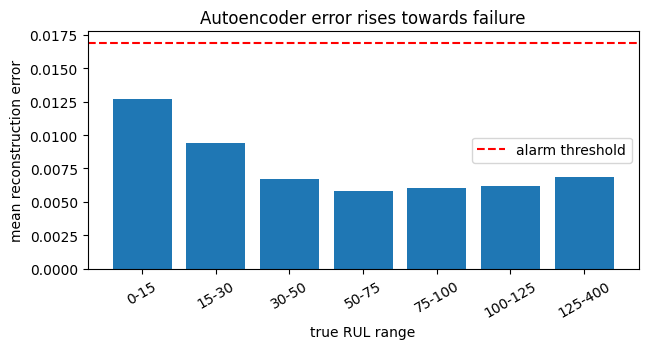

In [12]:
# ============ 11. Autoencoder anomaly detector ============
class DenseAE(nn.Module):
    def __init__(self, d, bottleneck=16):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d, 128), nn.ReLU(), nn.Linear(128, 48), nn.ReLU(), nn.Linear(48, bottleneck))
        self.dec = nn.Sequential(nn.Linear(bottleneck, 48), nn.ReLU(), nn.Linear(48, 128), nn.ReLU(), nn.Linear(128, d))
    def forward(self, x):
        return self.dec(self.enc(x))

@torch.no_grad()
def ae_errors(model, X, bs=2048):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).reshape(len(X[i:i + bs]), -1).to(DEVICE)
        out.append(((model(xb) - xb) ** 2).mean(1).cpu().numpy())
    return np.concatenate(out)

prep1, test1 = RUNS["FD001"]["prep"], RUNS["FD001"]["tests"]["FD001"]
Xh = prep1["Xtr"][prep1["ytr"] >= CAP]; Xh_val = prep1["Xva"][prep1["yva"] >= CAP]
print(f"Healthy windows: {len(Xh)} train, {len(Xh_val)} validation")

set_seed(0)
ae = DenseAE(Xh.shape[1] * Xh.shape[2]).to(DEVICE)
opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
Xt = torch.from_numpy(Xh).reshape(len(Xh), -1).to(DEVICE)
g = torch.Generator(); g.manual_seed(0)
best, best_state, wait = float("inf"), None, 0
for ep in range(CFG["AE_EPOCHS"]):
    ae.train(); perm = torch.randperm(len(Xt), generator=g).to(DEVICE)
    for i in range(0, len(Xt), 256):
        xb = Xt[perm[i:i + 256]]
        opt.zero_grad(); loss = ((ae(xb) - xb) ** 2).mean(); loss.backward(); opt.step()
    v = float(ae_errors(ae, Xh_val).mean())
    if v < best - 1e-7:
        best, wait = v, 0; best_state = {k: t.detach().clone() for k, t in ae.state_dict().items()}
    else:
        wait += 1
        if wait >= 10: break
ae.load_state_dict(best_state)

THR = float(np.percentile(ae_errors(ae, Xh_val), 99))
err_all = ae_errors(ae, test1["X_all"]); yr = test1["y_all_raw"]
AE_RES = evaluate_detector(err_all, yr, test1["unit_all"], THR)
print(f"\nThreshold (99th pct of healthy validation error): {THR:.5f}")
print(f"Test windows: {AE_RES['n_healthy']} healthy, {AE_RES['n_near']} near-failure (RUL<=30)")
print(f"AUROC = {AE_RES['auroc']:.3f} | precision = {AE_RES['precision']:.3f} | recall = {AE_RES['recall']:.3f} | F1 = {AE_RES['f1']:.3f}")
print(f"\nAlarm behaviour on {test1['n_engines']} test engines (alarm = 3 consecutive cycles above threshold):")
print(f"  early warning (alarm while RUL < {CAP}): {AE_RES['warned']} | false alarm (alarm while still healthy): {AE_RES['false_alarm']} | no alarm in observed data: {AE_RES['silent']}")
if AE_RES["warned"]: print(f"  warning given: median {AE_RES['median_lead']:.0f} cycles before failure (mean {AE_RES['mean_lead']:.0f})")
print("  Note: test engines are cut off before failure, so 'no alarm' can simply mean the engine was still healthy.")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
edges = np.array([0, 15, 30, 50, 75, 100, 125, 400]); lab = pd.cut(yr, edges, right=False)
mean_err = pd.Series(err_all).groupby(lab, observed=True).mean()
ax.bar(range(len(mean_err)), mean_err.values); ax.axhline(THR, c="r", ls="--", label="alarm threshold")
ax.set_xticks(range(len(mean_err))); ax.set_xticklabels([f"{int(i.left)}-{int(i.right)}" for i in mean_err.index], rotation=30)
ax.set_xlabel("true RUL range"); ax.set_ylabel("mean reconstruction error"); ax.legend(); ax.set_title("Autoencoder error rises towards failure")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/ae_error_vs_rul.png", dpi=130); plt.show()

In [13]:

def get(tr, te, model, col): return ALL[(ALL.Train == tr) & (ALL.Test == te) & (ALL.Model == model)][col]
def rm(tr, te, model): return pm(get(tr, te, model, "RMSE"))
def mean_rmse(tr, te, model): return float(get(tr, te, model, "RMSE").mean())

best_cls_11 = min(mean_rmse("FD001", "FD001", m) for m in BASELINE_NAMES[1:])
lstm_11, tr_11 = mean_rmse("FD001", "FD001", "LSTM"), mean_rmse("FD001", "FD001", "Transformer")
better = "LSTM" if lstm_11 <= tr_11 else "Transformer"; best_11 = min(lstm_11, tr_11)
mean_11 = mean_rmse("FD001", "FD001", "Mean predictor")

print("=" * 78)
print("RESULTS SUMMARY (mean ± std over seeds, official test engines, RUL capped at", CAP, ")")
print("=" * 78)
for model in ["Mean predictor", "Ridge (flattened window)", "Random forest (engineered feats)", "LSTM", "Transformer"]:
    print(f"FD001 → FD001  {model:<34} RMSE {rm('FD001','FD001',model)}")
for model in ["LSTM", "Transformer"]:
    print(f"FD003 → FD003  {model:<34} RMSE {rm('FD003','FD003',model)}")
    print(f"FD001 → FD003  {model:<34} RMSE {rm('FD001','FD003',model)}  (zero-shot)")
print(f"\nBest deep model on FD001: {better}, RMSE {best_11:.2f}")
print(f"  vs mean predictor ({mean_11:.2f}):     {(mean_11 - best_11) / mean_11 * 100:+.1f}%")
print(f"  vs best classical model ({best_cls_11:.2f}): {(best_cls_11 - best_11) / best_cls_11 * 100:+.1f}%   (negative = deep model did NOT beat it)")
print(f"Autoencoder: AUROC {AE_RES['auroc']:.2f}, F1 {AE_RES['f1']:.2f}")

print("\n" + "=" * 78)
print("SUGGESTED RESUME BULLETS (generated from this run; edit wording, never the numbers)")
print("=" * 78)
print(f"* Built leakage-free RUL pipeline on NASA C-MAPSS (engine-level split, train-only scaling); compared LSTM and Transformer\n"
      f"  against mean-predictor, Ridge and Random-Forest baselines over {len(CFG['SEEDS'])} seeds; best neural model ({better}) reached\n"
      f"  RMSE {rm('FD001','FD001',better)} on FD001 and {rm('FD003','FD003',better)} on FD003, "
      f"a {(mean_11 - best_11) / mean_11 * 100:.0f}% reduction vs the mean-predictor baseline (best classical baseline: RMSE {best_cls_11:.2f} on FD001).")
print(f"* Evaluated zero-shot transfer FD001→FD003 (RMSE {rm('FD001','FD003',better)}) with the asymmetric NASA PHM08 score, bootstrap CIs and ablations.")
print(f"* Trained an autoencoder on healthy engine states only; calibrated threshold on held-out engines gave AUROC {AE_RES['auroc']:.2f} for detecting\n"
      f"  near-failure windows (RUL ≤ 30).")
if best_cls_11 < best_11:
    print("\nHONEST NOTE: a classical model beat the deep models on FD001. Say so in the interview and explain why (small data, 100 engines).")
RESULTS.to_csv(f"{OUT_DIR}/results_table.csv", index=False)
shutil.make_archive("rul_results", "zip", OUT_DIR)
print("\nSaved tables and figures to ./outputs and ./rul_results.zip")
try:
    from google.colab import files
    files.download("rul_results.zip")
except Exception:
    pass

RESULTS SUMMARY (mean ± std over seeds, official test engines, RUL capped at 125 )
FD001 → FD001  Mean predictor                     RMSE 40.58
FD001 → FD001  Ridge (flattened window)           RMSE 14.72
FD001 → FD001  Random forest (engineered feats)   RMSE 12.81
FD001 → FD001  LSTM                               RMSE 13.38 ± 0.17
FD001 → FD001  Transformer                        RMSE 13.14 ± 0.55
FD003 → FD003  LSTM                               RMSE 12.59 ± 0.67
FD001 → FD003  LSTM                               RMSE 49.11 ± 0.03  (zero-shot)
FD003 → FD003  Transformer                        RMSE 13.54 ± 0.79
FD001 → FD003  Transformer                        RMSE 38.72 ± 3.54  (zero-shot)

Best deep model on FD001: Transformer, RMSE 13.14
  vs mean predictor (40.58):     +67.6%
  vs best classical model (12.81): -2.5%   (negative = deep model did NOT beat it)
Autoencoder: AUROC 0.76, F1 0.09

SUGGESTED RESUME BULLETS (generated from this run; edit wording, never the numbers)
* Built 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>